In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os

data_path = '/content/drive/MyDrive/skin-cancer-fusion/data'
print("Contents of your data folder:")
for item in os.listdir(data_path):
    print(" -", item)

Mounted at /content/drive
Contents of your data folder:
 - imgs_part_2.zip
 - imgs_part_3.zip
 - imgs_part_1.zip
 - metadata.csv


In [ ]:
import zipfile
import os

data_path = '/content/drive/MyDrive/skin-cancer-fusion/data'
extract_path = '/content/images'

os.makedirs(extract_path, exist_ok=True)

zip_files = ['imgs_part_1.zip', 'imgs_part_2.zip', 'imgs_part_3.zip']

for zip_name in zip_files:
    zip_path = os.path.join(data_path, zip_name)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Extracted: {zip_name}")

print("\nDone. Contents of extract folder:")
for item in os.listdir(extract_path):
    print(" -", item)

Extracted: imgs_part_1.zip
Extracted: imgs_part_2.zip
Extracted: imgs_part_3.zip

Done. Contents of extract folder:
 - imgs_part_2
 - imgs_part_1
 - imgs_part_3


In [ ]:
import os

# Peek inside imgs_part_1 to see the real structure
sample_folder = '/content/images/imgs_part_1'
contents = os.listdir(sample_folder)
print("First 5 items inside imgs_part_1:")
for item in contents[:5]:
    print(" -", item)
print(f"\nTotal items in imgs_part_1: {len(contents)}")

First 5 items inside imgs_part_1:
 - PAT_564_1079_31.png
 - PAT_394_794_235.png
 - PAT_172_267_557.png
 - PAT_87_133_159.png
 - PAT_281_432_813.png

Total items in imgs_part_1: 911


In [ ]:
import pandas as pd
import os

# Load metadata
csv_path = '/content/drive/MyDrive/skin-cancer-fusion/data/metadata.csv'
df = pd.read_csv(csv_path)

print("Total rows in CSV:", len(df))
print("\nLabel counts (diagnostic column):")
print(df['diagnostic'].value_counts())

# Build a lookup of all image filenames across all 3 folders
image_folders = ['/content/images/imgs_part_1', '/content/images/imgs_part_2', '/content/images/imgs_part_3']

image_lookup = {}  # filename -> full path
for folder in image_folders:
    for fname in os.listdir(folder):
        image_lookup[fname] = os.path.join(folder, fname)

print(f"\nTotal image files found across all folders: {len(image_lookup)}")

# Check each row's img_id against the lookup
found = 0
missing = 0
missing_examples = []

for img_name in df['img_id']:
    if img_name in image_lookup:
        found += 1
    else:
        missing += 1
        if len(missing_examples) < 5:
            missing_examples.append(img_name)

print(f"\nRows with matching image: {found}")
print(f"Rows with missing image: {missing}")
if missing_examples:
    print("Example missing filenames:", missing_examples)

Total rows in CSV: 2298

Label counts (diagnostic column):
diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

Total image files found across all folders: 2298

Rows with matching image: 2298
Rows with missing image: 0


In [ ]:
# See all column names
print("All columns:")
print(df.columns.tolist())

# Check missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

# Look at a few sample rows
df.head()

All columns:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

Missing values per column:
patient_id               0
lesion_id                0
smoke                  804
drink                  804
background_father      818
background_mother      822
age                      0
pesticide              804
gender                 804
skin_cancer_history    804
cancer_history         804
has_piped_water        804
has_sewage_system      804
fitspatrick            804
region                   0
diameter_1             804
diameter_2             804
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True


In [ ]:
# Check if the missingness lines up with biopsed status
print("Rows where 'gender' is missing, broken down by biopsed:")
print(df[df['gender'].isnull()]['biopsed'].value_counts())

print("\nRows where 'gender' is NOT missing, broken down by biopsed:")
print(df[df['gender'].notnull()]['biopsed'].value_counts())

# Check the actual unique values in the UNK-style columns
for col in ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']:
    print(f"\nUnique values in '{col}':", df[col].unique())

Rows where 'gender' is missing, broken down by biopsed:
biopsed
False    804
Name: count, dtype: int64

Rows where 'gender' is NOT missing, broken down by biopsed:
biopsed
True     1342
False     152
Name: count, dtype: int64

Unique values in 'itch': ['False' 'True' 'UNK']

Unique values in 'grew': ['False' 'True' 'UNK']

Unique values in 'hurt': ['False' 'True' 'UNK']

Unique values in 'changed': ['False' 'True' 'UNK']

Unique values in 'bleed': ['False' 'True' 'UNK']

Unique values in 'elevation': ['False' 'True' 'UNK']


In [ ]:
# Filter to biopsy-confirmed rows with complete metadata
df_clean = df[(df['biopsed'] == True) & (df['gender'].notnull())].copy()

print("Rows in cleaned subset:", len(df_clean))
print("\nLabel counts in cleaned subset:")
print(df_clean['diagnostic'].value_counts())

# Fix the UNK-style columns: convert to a 3-category string (not boolean)
symptom_cols = ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']
for col in symptom_cols:
    print(f"\n{col} value counts in cleaned subset:")
    print(df_clean[col].value_counts())

Rows in cleaned subset: 1342

Label counts in cleaned subset:
diagnostic
BCC    845
SCC    192
ACK    178
NEV     60
MEL     52
SEK     15
Name: count, dtype: int64

itch value counts in cleaned subset:
itch
True     943
False    393
UNK        6
Name: count, dtype: int64

grew value counts in cleaned subset:
grew
True     618
UNK      402
False    322
Name: count, dtype: int64

hurt value counts in cleaned subset:
hurt
False    956
True     376
UNK       10
Name: count, dtype: int64

changed value counts in cleaned subset:
changed
False    778
UNK      396
True     168
Name: count, dtype: int64

bleed value counts in cleaned subset:
bleed
False    780
True     556
UNK        6
Name: count, dtype: int64

elevation value counts in cleaned subset:
elevation
True     1018
False     322
UNK         2
Name: count, dtype: int64


In [ ]:
symptom_cols = ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']
for col in symptom_cols:
    df_clean[col] = df_clean[col].astype(str)  # keeps UNK as its own value

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_clean, test_size=0.3, stratify=df_clean['diagnostic'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['diagnostic'], random_state=42
)

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))
print("\nTrain label counts:")
print(train_df['diagnostic'].value_counts())

Train: 939
Val: 201
Test: 202

Train label counts:
diagnostic
BCC    591
SCC    134
ACK    125
NEV     42
MEL     36
SEK     11
Name: count, dtype: int64


In [ ]:
import pandas as pd

# Categorical columns to one-hot encode
cat_cols = ['gender', 'smoke', 'drink', 'pesticide', 'skin_cancer_history',
            'cancer_history', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation',
            'region', 'background_father', 'background_mother']

def encode_metadata(df, cat_cols, numeric_cols, reference_columns=None):
    df_cat = pd.get_dummies(df[cat_cols].astype(str))
    df_num = df[numeric_cols].fillna(df[numeric_cols].median())
    df_encoded = pd.concat([df_num, df_cat], axis=1)
    if reference_columns is not None:
        df_encoded = df_encoded.reindex(columns=reference_columns, fill_value=0)
    return df_encoded

numeric_cols = ['age', 'fitspatrick', 'diameter_1', 'diameter_2']

train_meta = encode_metadata(train_df, cat_cols, numeric_cols)
val_meta = encode_metadata(val_df, cat_cols, numeric_cols, reference_columns=train_meta.columns)
test_meta = encode_metadata(test_df, cat_cols, numeric_cols, reference_columns=train_meta.columns)

print("Feature count:", train_meta.shape[1])
train_meta.head()

Feature count: 70


,age,fitspatrick,diameter_1,diameter_2,gender_FEMALE,gender_MALE,smoke_False,smoke_True,drink_False,drink_True,...,background_mother_FRANCE,background_mother_GERMANY,background_mother_ITALY,background_mother_NETHERLANDS,background_mother_NORWAY,background_mother_POLAND,background_mother_POMERANIA,background_mother_PORTUGAL,background_mother_SPAIN,background_mother_UNK
1364,59,2.0,6.0,4.0,True,False,True,False,True,False,...,False,False,False,False,False,False,True,False,False,False
432,71,2.0,15.0,13.0,False,True,True,False,True,False,...,False,False,False,False,False,False,True,False,False,False
2094,58,3.0,12.0,6.0,False,True,True,False,True,False,...,False,True,False,False,False,False,False,False,False,False
1455,78,1.0,11.0,10.0,False,True,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
144,70,2.0,11.0,9.0,False,True,True,False,False,True,...,False,True,False,False,False,False,False,False,False,False


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(train_df['diagnostic'])

train_labels = le.transform(train_df['diagnostic'])
val_labels = le.transform(val_df['diagnostic'])
test_labels = le.transform(test_df['diagnostic'])

print("Classes:", le.classes_)
print("Example encoded labels:", train_labels[:5])

Classes: ['ACK' 'BCC' 'MEL' 'NEV' 'SCC' 'SEK']
Example encoded labels: [1 1 1 1 4]


In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms
import os

class SkinFusionDataset(Dataset):
    def __init__(self, df, meta_features, labels, image_folders, transform=None):
        self.df = df.reset_index(drop=True)
        self.meta_features = meta_features.reset_index(drop=True)
        self.labels = labels
        self.image_folders = image_folders
        self.transform = transform
        self.image_lookup = {}
        for folder in image_folders:
            for fname in os.listdir(folder):
                self.image_lookup[fname] = os.path.join(folder, fname)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'img_id']
        img_path = self.image_lookup[img_name]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)

        meta = torch.tensor(self.meta_features.iloc[idx].values.astype('float32'))
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        return image, meta, label

In [ ]:
image_folders = ['/content/images/imgs_part_1', '/content/images/imgs_part_2', '/content/images/imgs_part_3']

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = SkinFusionDataset(train_df, train_meta, train_labels, image_folders, transform)
val_dataset = SkinFusionDataset(val_df, val_meta, val_labels, image_folders, transform)
test_dataset = SkinFusionDataset(test_df, test_meta, test_labels, image_folders, transform)

# Test one sample
image, meta, label = train_dataset[0]
print("Image shape:", image.shape)
print("Meta shape:", meta.shape)
print("Label:", label)

Image shape: torch.Size([3, 224, 224])
Meta shape: torch.Size([70])
Label: tensor(1)


In [ ]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Test one batch
images, metas, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch meta shape:", metas.shape)
print("Batch labels shape:", labels.shape)

Batch image shape: torch.Size([32, 3, 224, 224])
Batch meta shape: torch.Size([32, 70])
Batch labels shape: torch.Size([32])


In [ ]:
import torch.nn as nn
import torchvision.models as models

class FusionModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()

        # Image branch: pretrained ResNet18
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])  # remove final FC
        self.image_out_dim = 512

        # Metadata branch: simple MLP
        self.meta_branch = nn.Sequential(
            nn.Linear(meta_input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
        self.meta_out_dim = 32

        # Fusion + classifier
        self.classifier = nn.Sequential(
            nn.Linear(self.image_out_dim + self.meta_out_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        meta_feat = self.meta_branch(meta)
        combined = torch.cat([img_feat, meta_feat], dim=1)
        return self.classifier(combined)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

model = FusionModel(meta_input_dim=70, num_classes=6).to(device)
print(model)

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


FusionModel(
  (image_branch): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_st

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print("Class weights:", class_weights)

Class weights: tensor([ 1.2520,  0.2648,  4.3472,  3.7262,  1.1679, 14.2273], device='cuda:0')


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images, metas)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), correct / total

In [ ]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            outputs = model(images, metas)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total

In [ ]:
num_epochs = 15

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

Epoch 1/15 - Train loss: 1.6998, Train acc: 0.1278 - Val loss: 1.5965, Val acc: 0.3731
Epoch 2/15 - Train loss: 1.1738, Train acc: 0.3919 - Val loss: 1.5337, Val acc: 0.3483
Epoch 3/15 - Train loss: 0.7995, Train acc: 0.6262 - Val loss: 1.4510, Val acc: 0.5075
Epoch 4/15 - Train loss: 0.5292, Train acc: 0.7412 - Val loss: 1.5219, Val acc: 0.4726
Epoch 5/15 - Train loss: 0.3654, Train acc: 0.8498 - Val loss: 1.6034, Val acc: 0.4826
Epoch 6/15 - Train loss: 0.2102, Train acc: 0.9404 - Val loss: 1.6235, Val acc: 0.6070
Epoch 7/15 - Train loss: 0.1447, Train acc: 0.9755 - Val loss: 1.7881, Val acc: 0.6169
Epoch 8/15 - Train loss: 0.1003, Train acc: 0.9894 - Val loss: 1.7634, Val acc: 0.6070
Epoch 9/15 - Train loss: 0.0733, Train acc: 0.9936 - Val loss: 1.9055, Val acc: 0.6368
Epoch 10/15 - Train loss: 0.0602, Train acc: 0.9936 - Val loss: 2.1044, Val acc: 0.6418
Epoch 11/15 - Train loss: 0.0669, Train acc: 0.9787 - Val loss: 2.1729, Val acc: 0.6119
Epoch 12/15 - Train loss: 0.0536, Train a

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = SkinFusionDataset(train_df, train_meta, train_labels, image_folders, train_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [ ]:
model = FusionModel(meta_input_dim=70, num_classes=6).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [ ]:
best_val_acc = 0
num_epochs = 15

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_model.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 1.6751, Train acc: 0.2162 - Val loss: 1.5176, Val acc: 0.2935
  -> Saved new best model
Epoch 2/15 - Train loss: 1.3237, Train acc: 0.4324 - Val loss: 1.5210, Val acc: 0.3333
  -> Saved new best model
Epoch 3/15 - Train loss: 1.0301, Train acc: 0.5421 - Val loss: 1.4095, Val acc: 0.4080
  -> Saved new best model
Epoch 4/15 - Train loss: 0.8654, Train acc: 0.5399 - Val loss: 1.4791, Val acc: 0.5174
  -> Saved new best model
Epoch 5/15 - Train loss: 0.7175, Train acc: 0.6283 - Val loss: 1.6444, Val acc: 0.5025
Epoch 6/15 - Train loss: 0.5807, Train acc: 0.6773 - Val loss: 1.7164, Val acc: 0.5224
  -> Saved new best model
Epoch 7/15 - Train loss: 0.5121, Train acc: 0.7476 - Val loss: 1.9172, Val acc: 0.5323
  -> Saved new best model
Epoch 8/15 - Train loss: 0.4459, Train acc: 0.7689 - Val loss: 2.1959, Val acc: 0.4279
Epoch 9/15 - Train loss: 0.4176, Train acc: 0.8083 - Val loss: 1.9811, Val acc: 0.4826
Epoch 10/15 - Train loss: 0.3549, Train acc: 0.8104 - Val los

In [ ]:
model = FusionModel(meta_input_dim=70, num_classes=6).to(device)

# Freeze all ResNet layers except the last block (layer4) and the final pooling
for name, param in model.image_branch.named_parameters():
    if 'layer4' not in name:
        param.requires_grad = False

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)

print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable params: 41894


In [ ]:
best_val_acc = 0
num_epochs = 20

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_model.pth')
        print("  -> Saved new best model")

Epoch 1/20 - Train loss: 1.7857, Train acc: 0.2343 - Val loss: 1.7071, Val acc: 0.4428
  -> Saved new best model
Epoch 2/20 - Train loss: 1.7315, Train acc: 0.3056 - Val loss: 1.6644, Val acc: 0.4478
  -> Saved new best model
Epoch 3/20 - Train loss: 1.6874, Train acc: 0.3706 - Val loss: 1.6344, Val acc: 0.4975
  -> Saved new best model
Epoch 4/20 - Train loss: 1.6592, Train acc: 0.3280 - Val loss: 1.6018, Val acc: 0.4925
Epoch 5/20 - Train loss: 1.6284, Train acc: 0.4196 - Val loss: 1.5775, Val acc: 0.5323
  -> Saved new best model
Epoch 6/20 - Train loss: 1.5960, Train acc: 0.3642 - Val loss: 1.5458, Val acc: 0.5423
  -> Saved new best model
Epoch 7/20 - Train loss: 1.5666, Train acc: 0.4313 - Val loss: 1.5299, Val acc: 0.5323
Epoch 8/20 - Train loss: 1.5379, Train acc: 0.4089 - Val loss: 1.5062, Val acc: 0.6119
  -> Saved new best model
Epoch 9/20 - Train loss: 1.5261, Train acc: 0.4696 - Val loss: 1.4940, Val acc: 0.5124
Epoch 10/20 - Train loss: 1.4761, Train acc: 0.4260 - Val los

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

In [ ]:
best_val_acc = 0.5622

num_epochs = 10

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_model.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.2875, Train acc: 0.4196 - Val loss: 1.3488, Val acc: 0.5174
Epoch 2/10 - Train loss: 1.3075, Train acc: 0.4675 - Val loss: 1.3514, Val acc: 0.6070
  -> Saved new best model
Epoch 3/10 - Train loss: 1.2486, Train acc: 0.4334 - Val loss: 1.3313, Val acc: 0.5871
Epoch 4/10 - Train loss: 1.2386, Train acc: 0.4814 - Val loss: 1.3293, Val acc: 0.5821
Epoch 5/10 - Train loss: 1.2471, Train acc: 0.4728 - Val loss: 1.3079, Val acc: 0.5970
Epoch 6/10 - Train loss: 1.2603, Train acc: 0.4420 - Val loss: 1.3307, Val acc: 0.5821
Epoch 7/10 - Train loss: 1.2424, Train acc: 0.4665 - Val loss: 1.3083, Val acc: 0.5672
Epoch 8/10 - Train loss: 1.2002, Train acc: 0.4814 - Val loss: 1.3189, Val acc: 0.5970
Epoch 9/10 - Train loss: 1.2011, Train acc: 0.4952 - Val loss: 1.2961, Val acc: 0.5323
Epoch 10/10 - Train loss: 1.1439, Train acc: 0.4824 - Val loss: 1.2899, Val acc: 0.5970


In [ ]:
model.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_model.pth'))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

Test loss: 1.3961, Test acc: 0.5644


In [ ]:
class ImageOnlyModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        self.classifier = nn.Sequential(
            nn.Linear(512, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, image, meta=None):
        feat = self.image_branch(image).flatten(1)
        return self.classifier(feat)

In [ ]:
img_model = ImageOnlyModel(num_classes=6).to(device)
img_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, img_model.parameters()), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
num_epochs = 10

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(img_model, train_loader, criterion, img_optimizer, device)
    val_loss, val_acc = evaluate(img_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(img_model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_image_only.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.8049, Train acc: 0.1427 - Val loss: 1.7612, Val acc: 0.2289
  -> Saved new best model
Epoch 2/10 - Train loss: 1.7758, Train acc: 0.3312 - Val loss: 1.7326, Val acc: 0.4080
  -> Saved new best model
Epoch 3/10 - Train loss: 1.7428, Train acc: 0.3738 - Val loss: 1.7195, Val acc: 0.3881
Epoch 4/10 - Train loss: 1.7161, Train acc: 0.2918 - Val loss: 1.6969, Val acc: 0.3582
Epoch 5/10 - Train loss: 1.6604, Train acc: 0.3610 - Val loss: 1.6818, Val acc: 0.3881
Epoch 6/10 - Train loss: 1.6364, Train acc: 0.3482 - Val loss: 1.6660, Val acc: 0.4179
  -> Saved new best model
Epoch 7/10 - Train loss: 1.6458, Train acc: 0.3972 - Val loss: 1.6367, Val acc: 0.5473
  -> Saved new best model
Epoch 8/10 - Train loss: 1.6090, Train acc: 0.3759 - Val loss: 1.6179, Val acc: 0.4378
Epoch 9/10 - Train loss: 1.5694, Train acc: 0.3930 - Val loss: 1.6008, Val acc: 0.4876
Epoch 10/10 - Train loss: 1.5480, Train acc: 0.4324 - Val loss: 1.5922, Val acc: 0.5473


In [ ]:
img_model.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_image_only.pth'))
test_loss, test_acc = evaluate(img_model, test_loader, criterion, device)
print(f"Image-only Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

Image-only Test loss: 1.6146, Test acc: 0.5644


In [ ]:
class MetaOnlyModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        self.meta_branch = nn.Sequential(
            nn.Linear(meta_input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, num_classes)
        )

    def forward(self, image, meta):
        feat = self.meta_branch(meta)
        return self.classifier(feat)

In [ ]:
meta_model = MetaOnlyModel(meta_input_dim=70, num_classes=6).to(device)
meta_optimizer = torch.optim.Adam(meta_model.parameters(), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
num_epochs = 10

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(meta_model, train_loader, criterion, meta_optimizer, device)
    val_loss, val_acc = evaluate(meta_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(meta_model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_meta_only.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.8406, Train acc: 0.1565 - Val loss: 1.8239, Val acc: 0.1642
  -> Saved new best model
Epoch 2/10 - Train loss: 1.8078, Train acc: 0.1491 - Val loss: 1.7878, Val acc: 0.1642
Epoch 3/10 - Train loss: 1.7837, Train acc: 0.1683 - Val loss: 1.7693, Val acc: 0.1791
  -> Saved new best model
Epoch 4/10 - Train loss: 1.7760, Train acc: 0.1715 - Val loss: 1.7637, Val acc: 0.1791
Epoch 5/10 - Train loss: 1.7723, Train acc: 0.1906 - Val loss: 1.7582, Val acc: 0.1692
Epoch 6/10 - Train loss: 1.7672, Train acc: 0.2194 - Val loss: 1.7524, Val acc: 0.1940
  -> Saved new best model
Epoch 7/10 - Train loss: 1.7542, Train acc: 0.2204 - Val loss: 1.7495, Val acc: 0.1990
  -> Saved new best model
Epoch 8/10 - Train loss: 1.7902, Train acc: 0.2311 - Val loss: 1.7465, Val acc: 0.1791
Epoch 9/10 - Train loss: 1.7449, Train acc: 0.2705 - Val loss: 1.7402, Val acc: 0.2090
  -> Saved new best model
Epoch 10/10 - Train loss: 1.7490, Train acc: 0.2641 - Val loss: 1.7387, Val acc: 0.1891

In [ ]:
meta_model.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_meta_only.pth'))
test_loss, test_acc = evaluate(meta_model, test_loader, criterion, device)
print(f"Meta-only Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

Meta-only Test loss: 1.7470, Test acc: 0.1584


In [ ]:
class MetaBlock(nn.Module):
    def __init__(self, image_feat_dim, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False

        # Metadata generates a gate that scales image features
        self.meta_gate = nn.Sequential(
            nn.Linear(meta_input_dim, image_feat_dim),
            nn.Sigmoid()
        )
        self.meta_bias = nn.Sequential(
            nn.Linear(meta_input_dim, image_feat_dim),
            nn.Tanh()
        )

        self.classifier = nn.Sequential(
            nn.Linear(image_feat_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        gate = self.meta_gate(meta)
        bias = self.meta_bias(meta)
        modulated = img_feat * gate + bias
        return self.classifier(modulated)

In [ ]:
metablock_model = MetaBlock(image_feat_dim=512, meta_input_dim=70, num_classes=6).to(device)
metablock_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, metablock_model.parameters()), lr=1e-4, weight_decay=1e-4)

best_val_acc = 0
num_epochs = 10

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(metablock_model, train_loader, criterion, metablock_optimizer, device)
    val_loss, val_acc = evaluate(metablock_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/{num_epochs} - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_metablock.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.7928, Train acc: 0.1672 - Val loss: 1.7507, Val acc: 0.1841
  -> Saved new best model
Epoch 2/10 - Train loss: 1.7439, Train acc: 0.2737 - Val loss: 1.7144, Val acc: 0.2637
  -> Saved new best model
Epoch 3/10 - Train loss: 1.7210, Train acc: 0.4217 - Val loss: 1.6981, Val acc: 0.3085
  -> Saved new best model
Epoch 4/10 - Train loss: 1.7080, Train acc: 0.3078 - Val loss: 1.6678, Val acc: 0.3085
Epoch 5/10 - Train loss: 1.6461, Train acc: 0.3876 - Val loss: 1.6548, Val acc: 0.2040
Epoch 6/10 - Train loss: 1.6435, Train acc: 0.2790 - Val loss: 1.6385, Val acc: 0.1990
Epoch 7/10 - Train loss: 1.5884, Train acc: 0.3003 - Val loss: 1.6151, Val acc: 0.2090
Epoch 8/10 - Train loss: 1.5754, Train acc: 0.3770 - Val loss: 1.5959, Val acc: 0.2139
Epoch 9/10 - Train loss: 1.5391, Train acc: 0.3419 - Val loss: 1.5725, Val acc: 0.2736
Epoch 10/10 - Train loss: 1.5262, Train acc: 0.3866 - Val loss: 1.5554, Val acc: 0.2438


In [ ]:
for epoch in range(10):
    train_loss, train_acc = train_one_epoch(metablock_model, train_loader, criterion, metablock_optimizer, device)
    val_loss, val_acc = evaluate(metablock_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/10 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_metablock.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.4974, Train acc: 0.4696 - Val loss: 1.5338, Val acc: 0.2189
Epoch 2/10 - Train loss: 1.4594, Train acc: 0.3206 - Val loss: 1.5128, Val acc: 0.2637
Epoch 3/10 - Train loss: 1.4421, Train acc: 0.3546 - Val loss: 1.4915, Val acc: 0.2388
Epoch 4/10 - Train loss: 1.4318, Train acc: 0.3663 - Val loss: 1.4599, Val acc: 0.3035
Epoch 5/10 - Train loss: 1.4048, Train acc: 0.3834 - Val loss: 1.4498, Val acc: 0.2438
Epoch 6/10 - Train loss: 1.3626, Train acc: 0.3663 - Val loss: 1.4195, Val acc: 0.3184
  -> Saved new best model
Epoch 7/10 - Train loss: 1.3703, Train acc: 0.4207 - Val loss: 1.3986, Val acc: 0.4527
  -> Saved new best model
Epoch 8/10 - Train loss: 1.3240, Train acc: 0.4271 - Val loss: 1.3776, Val acc: 0.3682
Epoch 9/10 - Train loss: 1.2872, Train acc: 0.4239 - Val loss: 1.3612, Val acc: 0.4129
Epoch 10/10 - Train loss: 1.3017, Train acc: 0.4164 - Val loss: 1.3438, Val acc: 0.4229


In [ ]:
for epoch in range(10):
    train_loss, train_acc = train_one_epoch(metablock_model, train_loader, criterion, metablock_optimizer, device)
    val_loss, val_acc = evaluate(metablock_model, val_loader, criterion, device)
    print(f"Epoch {epoch+1}/10 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_model.state_dict(), '/content/drive/MyDrive/skin-cancer-fusion/best_metablock.pth')
        print("  -> Saved new best model")

Epoch 1/10 - Train loss: 1.2619, Train acc: 0.4388 - Val loss: 1.3260, Val acc: 0.4328
Epoch 2/10 - Train loss: 1.2391, Train acc: 0.4015 - Val loss: 1.3087, Val acc: 0.4677
  -> Saved new best model
Epoch 3/10 - Train loss: 1.2136, Train acc: 0.4931 - Val loss: 1.2939, Val acc: 0.4279
Epoch 4/10 - Train loss: 1.2202, Train acc: 0.4569 - Val loss: 1.2775, Val acc: 0.4279
Epoch 5/10 - Train loss: 1.1643, Train acc: 0.4377 - Val loss: 1.2548, Val acc: 0.4627
Epoch 6/10 - Train loss: 1.1699, Train acc: 0.4931 - Val loss: 1.2515, Val acc: 0.4428
Epoch 7/10 - Train loss: 1.1658, Train acc: 0.4792 - Val loss: 1.2303, Val acc: 0.4428
Epoch 8/10 - Train loss: 1.1199, Train acc: 0.5027 - Val loss: 1.2248, Val acc: 0.5274
  -> Saved new best model
Epoch 9/10 - Train loss: 1.1210, Train acc: 0.5016 - Val loss: 1.2155, Val acc: 0.4229
Epoch 10/10 - Train loss: 1.0873, Train acc: 0.4835 - Val loss: 1.1893, Val acc: 0.5075


In [ ]:
metablock_model.load_state_dict(torch.load('/content/drive/MyDrive/skin-cancer-fusion/best_metablock.pth'))
test_loss, test_acc = evaluate(metablock_model, test_loader, criterion, device)
print(f"MetaBlock Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

MetaBlock Test loss: 1.2843, Test acc: 0.5842


In [ ]:
import numpy as np

def compute_ablation_importance(model, loader, device):
    model.eval()
    results = {'true_label': [], 'baseline_prob': [], 'no_image_prob': [], 'no_meta_prob': []}

    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)

            # Baseline: both modalities present
            baseline_out = torch.softmax(model(images, metas), dim=1)

            # Ablate image: replace with zeros
            zero_images = torch.zeros_like(images)
            no_image_out = torch.softmax(model(zero_images, metas), dim=1)

            # Ablate metadata: replace with zeros
            zero_metas = torch.zeros_like(metas)
            no_meta_out = torch.softmax(model(images, zero_metas), dim=1)

            for i in range(labels.size(0)):
                label = labels[i].item()
                results['true_label'].append(label)
                results['baseline_prob'].append(baseline_out[i, label].item())
                results['no_image_prob'].append(no_image_out[i, label].item())
                results['no_meta_prob'].append(no_meta_out[i, label].item())

    return pd.DataFrame(results)

ablation_df = compute_ablation_importance(model, test_loader, device)
ablation_df['image_importance'] = ablation_df['baseline_prob'] - ablation_df['no_image_prob']
ablation_df['meta_importance'] = ablation_df['baseline_prob'] - ablation_df['no_meta_prob']

print(ablation_df[['image_importance', 'meta_importance']].describe())

       image_importance  meta_importance
count        202.000000       202.000000
mean           0.168661        -0.008113
std            0.114699         0.065653
min           -0.218178        -0.244630
25%            0.088625        -0.051695
50%            0.165766        -0.010497
75%            0.245185         0.036031
max            0.518510         0.159933


In [ ]:
def compute_none_prob(model, loader, device):
    model.eval()
    none_probs = []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            zero_images = torch.zeros_like(images)
            zero_metas = torch.zeros_like(metas)
            none_out = torch.softmax(model(zero_images, zero_metas), dim=1)
            for i in range(labels.size(0)):
                none_probs.append(none_out[i, labels[i].item()].item())
    return none_probs

ablation_df['none_prob'] = compute_none_prob(model, test_loader, device)

# Exact Shapley values for 2 players
ablation_df['shapley_image'] = 0.5 * (ablation_df['no_meta_prob'] - ablation_df['none_prob']) + \
                                 0.5 * (ablation_df['baseline_prob'] - ablation_df['no_image_prob'])
ablation_df['shapley_meta'] = 0.5 * (ablation_df['no_image_prob'] - ablation_df['none_prob']) + \
                                0.5 * (ablation_df['baseline_prob'] - ablation_df['no_meta_prob'])

print(ablation_df[['shapley_image', 'shapley_meta']].describe())

       shapley_image  shapley_meta
count     202.000000    202.000000
mean        0.191088      0.014314
std         0.123079      0.050368
min        -0.221644     -0.228025
25%         0.100167     -0.015043
50%         0.193510      0.006869
75%         0.287219      0.034152
max         0.530076      0.147787


In [ ]:
from scipy.stats import spearmanr

corr_image, p_image = spearmanr(ablation_df['image_importance'], ablation_df['shapley_image'])
corr_meta, p_meta = spearmanr(ablation_df['meta_importance'], ablation_df['shapley_meta'])

print(f"Ablation vs Shapley (image): rho={corr_image:.3f}, p={p_image:.4f}")
print(f"Ablation vs Shapley (meta): rho={corr_meta:.3f}, p={p_meta:.4f}")

Ablation vs Shapley (image): rho=0.980, p=0.0000
Ablation vs Shapley (meta): rho=0.978, p=0.0000


In [ ]:
!pip install captum -q

from captum.attr import IntegratedGradients

def compute_ig_importance(model, loader, device):
    model.eval()
    ig_image_scores = []
    ig_meta_scores = []

    def forward_func(images, metas):
        return model(images, metas)

    ig = IntegratedGradients(forward_func)

    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        images.requires_grad_()
        metas.requires_grad_()

        for i in range(labels.size(0)):
            img_single = images[i:i+1]
            meta_single = metas[i:i+1]
            label = labels[i].item()

            attributions = ig.attribute((img_single, meta_single), target=label, n_steps=20)
            img_attr, meta_attr = attributions

            ig_image_scores.append(img_attr.abs().sum().item())
            ig_meta_scores.append(meta_attr.abs().sum().item())

    return ig_image_scores, ig_meta_scores

ig_image, ig_meta = compute_ig_importance(model, test_loader, device)
ablation_df['ig_image'] = ig_image
ablation_df['ig_meta'] = ig_meta

print(ablation_df[['ig_image', 'ig_meta']].describe())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 16.2 MB/s eta 0:00:00
          ig_image     ig_meta
count   202.000000  202.000000
mean    505.530317    0.436650
std     221.422436    0.270054
min      97.540649    0.114218
25%     349.899605    0.249970
50%     460.304810    0.332284
75%     613.568970    0.539258
max    1348.542114    1.580092


In [ ]:
corr_ig_image, p_ig_image = spearmanr(ablation_df['image_importance'], ablation_df['ig_image'])
corr_ig_meta, p_ig_meta = spearmanr(ablation_df['meta_importance'], ablation_df['ig_meta'])

print(f"Ablation vs IG (image): rho={corr_ig_image:.3f}, p={p_ig_image:.4f}")
print(f"Ablation vs IG (meta): rho={corr_ig_meta:.3f}, p={p_ig_meta:.4f}")

Ablation vs IG (image): rho=0.242, p=0.0005
Ablation vs IG (meta): rho=0.571, p=0.0000


In [ ]:
from sklearn.utils import resample

n_bootstrap = 1000
bootstrap_means = []

for _ in range(n_bootstrap):
    sample = resample(ablation_df['image_importance'], n_samples=len(ablation_df))
    bootstrap_means.append(sample.mean())

ci_lower = np.percentile(bootstrap_means, 2.5)
ci_upper = np.percentile(bootstrap_means, 97.5)
print(f"Ablation image_importance mean: {ablation_df['image_importance'].mean():.4f}")
print(f"95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

Ablation image_importance mean: 0.1687
95% CI: [0.1523, 0.1841]


In [ ]:
import copy

# Create a randomized version of the model (same architecture, random weights)
random_model = FusionModel(meta_input_dim=70, num_classes=6).to(device)
# Don't load any trained weights — leave it randomly initialized

random_ig_image, random_ig_meta = compute_ig_importance(random_model, test_loader, device)

# Compare: does IG on random model correlate with IG on trained model?
corr_sanity, p_sanity = spearmanr(ig_image, random_ig_image)
print(f"Trained-model IG vs Random-model IG (image): rho={corr_sanity:.3f}, p={p_sanity:.4f}")

Trained-model IG vs Random-model IG (image): rho=0.832, p=0.0000


In [ ]:
def make_truly_random_model(meta_input_dim, num_classes):
    model = FusionModel(meta_input_dim=meta_input_dim, num_classes=num_classes)
    # Reinitialize ALL image branch weights randomly, overriding the pretrained ones
    for module in model.image_branch.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    return model.to(device)

random_model = make_truly_random_model(meta_input_dim=70, num_classes=6)

random_ig_image, random_ig_meta = compute_ig_importance(random_model, test_loader, device)
corr_sanity, p_sanity = spearmanr(ig_image, random_ig_image)
print(f"Trained-model IG vs TRULY-random-model IG (image): rho={corr_sanity:.3f}, p={p_sanity:.4f}")

Trained-model IG vs TRULY-random-model IG (image): rho=0.762, p=0.0000


In [ ]:
def compute_gate_importance(metablock_model, loader, device):
    metablock_model.eval()
    gate_scores = []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas = images.to(device), metas.to(device)
            gate = metablock_model.meta_gate(metas)
            gate_scores.extend(gate.mean(dim=1).cpu().numpy())
    return gate_scores

gate_scores = compute_gate_importance(metablock_model, test_loader, device)
ablation_df['gate_image'] = gate_scores

corr_gate, p_gate = spearmanr(ablation_df['image_importance'], ablation_df['gate_image'])
print(f"Ablation vs Gate weights (image): rho={corr_gate:.3f}, p={p_gate:.4f}")

Ablation vs Gate weights (image): rho=0.111, p=0.1174


In [ ]:
def make_truly_random_metablock(image_feat_dim, meta_input_dim, num_classes):
    model = MetaBlock(image_feat_dim=image_feat_dim, meta_input_dim=meta_input_dim, num_classes=num_classes)
    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    return model.to(device)

random_metablock = make_truly_random_metablock(image_feat_dim=512, meta_input_dim=70, num_classes=6)
random_gate_scores = compute_gate_importance(random_metablock, test_loader, device)

corr_gate_sanity, p_gate_sanity = spearmanr(gate_scores, random_gate_scores)
print(f"Trained-gate vs Random-gate: rho={corr_gate_sanity:.3f}, p={p_gate_sanity:.4f}")

Trained-gate vs Random-gate: rho=-0.388, p=0.0000


In [ ]:
# Rank-transform each method for fair comparison (different scales)
ablation_df['rank_ablation'] = ablation_df['image_importance'].rank()
ablation_df['rank_ig'] = ablation_df['ig_image'].rank()
ablation_df['rank_gate'] = ablation_df['gate_image'].rank()

# Find cases where ablation and IG disagree most
ablation_df['ig_disagreement'] = (ablation_df['rank_ablation'] - ablation_df['rank_ig']).abs()
ablation_df['gate_disagreement'] = (ablation_df['rank_ablation'] - ablation_df['rank_gate']).abs()

# Top 5 disagreement cases for IG
top_ig_disagree = ablation_df.nlargest(5, 'ig_disagreement')
print("Top IG disagreement cases (index, true_label, ablation rank, IG rank):")
print(top_ig_disagree[['true_label', 'rank_ablation', 'rank_ig', 'image_importance', 'ig_image']])

# Top 5 disagreement cases for gate
top_gate_disagree = ablation_df.nlargest(5, 'gate_disagreement')
print("\nTop Gate disagreement cases:")
print(top_gate_disagree[['true_label', 'rank_ablation', 'rank_gate', 'image_importance', 'gate_image']])

Top IG disagreement cases (index, true_label, ablation rank, IG rank):
     true_label  rank_ablation  rank_ig  image_importance     ig_image
24            4           11.0    202.0         -0.003312  1348.542114
78            3            1.0    188.0         -0.218178   860.086487
145           4            7.0    192.0         -0.026650   906.937622
167           4           14.0    196.0          0.011017  1055.302979
181           1          190.0     24.0          0.345465   267.981323

Top Gate disagreement cases:
     true_label  rank_ablation  rank_gate  image_importance  gate_image
78            3            1.0      202.0         -0.218178    0.504948
184           3            5.0      199.0         -0.038040    0.501571
156           1          201.0       16.0          0.454221    0.480171
133           1          192.0        8.0          0.360240    0.479543
199           1          200.0       19.0          0.399799    0.480692


In [ ]:
print(ablation_df['gate_image'].describe())

count    202.000000
mean       0.485602
std        0.005043
min        0.477904
25%        0.481920
50%        0.484345
75%        0.488044
max        0.504948
Name: gate_image, dtype: float64


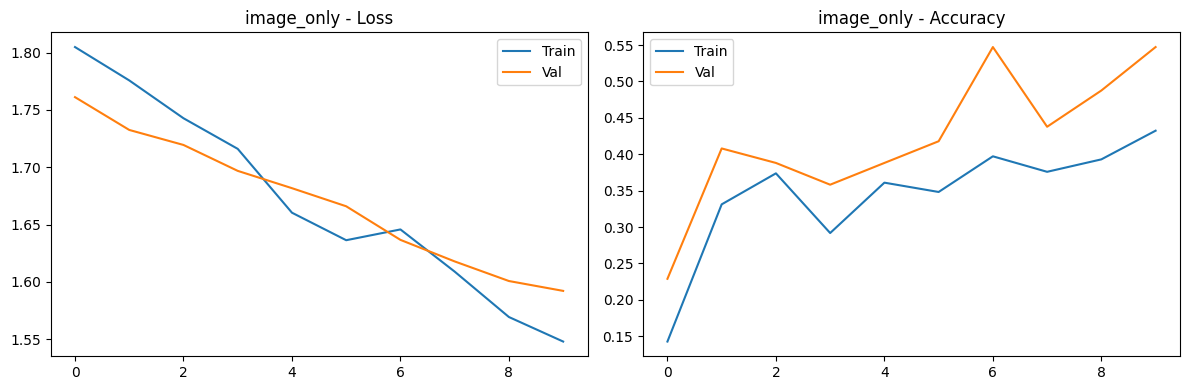

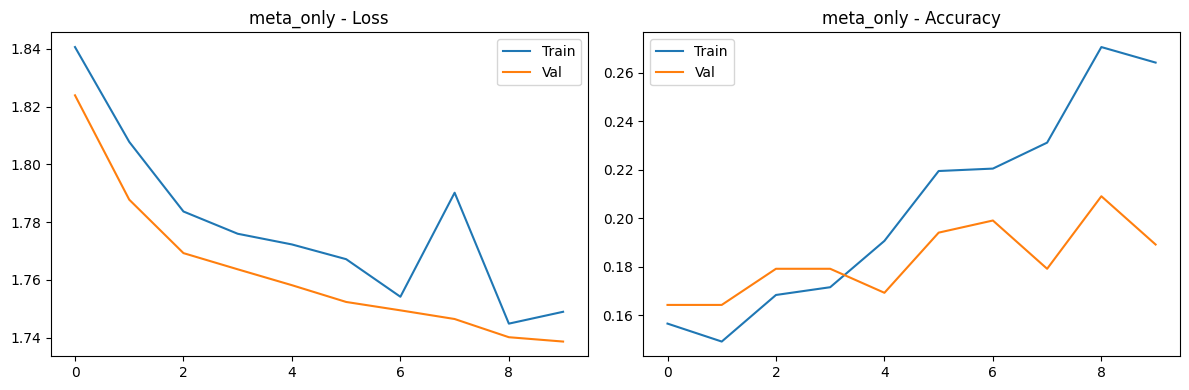

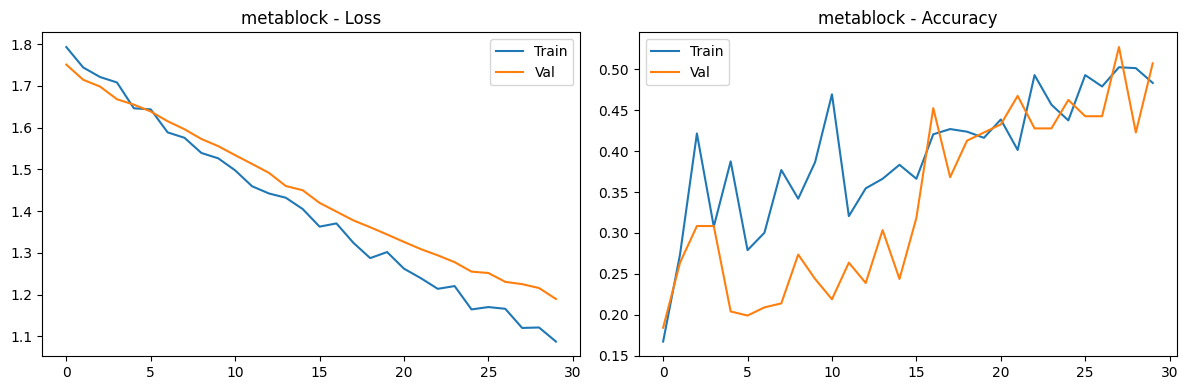

In [ ]:
import matplotlib.pyplot as plt

def plot_curves(train_loss, val_loss, train_acc, val_acc, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(train_loss, label='Train'); axes[0].plot(val_loss, label='Val')
    axes[0].set_title(f'{title} - Loss'); axes[0].legend()
    axes[1].plot(train_acc, label='Train'); axes[1].plot(val_acc, label='Val')
    axes[1].set_title(f'{title} - Accuracy'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/skin-cancer-fusion/curve_{title}.png')
    plt.show()

plot_curves(
    [1.8049,1.7758,1.7428,1.7161,1.6604,1.6364,1.6458,1.6090,1.5694,1.5480],
    [1.7612,1.7326,1.7195,1.6969,1.6818,1.6660,1.6367,1.6179,1.6008,1.5922],
    [0.1427,0.3312,0.3738,0.2918,0.3610,0.3482,0.3972,0.3759,0.3930,0.4324],
    [0.2289,0.4080,0.3881,0.3582,0.3881,0.4179,0.5473,0.4378,0.4876,0.5473],
    'image_only')

plot_curves(
    [1.8406,1.8078,1.7837,1.7760,1.7723,1.7672,1.7542,1.7902,1.7449,1.7490],
    [1.8239,1.7878,1.7693,1.7637,1.7582,1.7524,1.7495,1.7465,1.7402,1.7387],
    [0.1565,0.1491,0.1683,0.1715,0.1906,0.2194,0.2204,0.2311,0.2705,0.2641],
    [0.1642,0.1642,0.1791,0.1791,0.1692,0.1940,0.1990,0.1791,0.2090,0.1891],
    'meta_only')

plot_curves(
    [1.7928,1.7439,1.7210,1.7080,1.6461,1.6435,1.5884,1.5754,1.5391,1.5262,1.4974,1.4594,1.4421,1.4318,1.4048,1.3626,1.3703,1.3240,1.2872,1.3017,1.2619,1.2391,1.2136,1.2202,1.1643,1.1699,1.1658,1.1199,1.1210,1.0873],
    [1.7507,1.7144,1.6981,1.6678,1.6548,1.6385,1.6151,1.5959,1.5725,1.5554,1.5338,1.5128,1.4915,1.4599,1.4498,1.4195,1.3986,1.3776,1.3612,1.3438,1.3260,1.3087,1.2939,1.2775,1.2548,1.2515,1.2303,1.2248,1.2155,1.1893],
    [0.1672,0.2737,0.4217,0.3078,0.3876,0.2790,0.3003,0.3770,0.3419,0.3866,0.4696,0.3206,0.3546,0.3663,0.3834,0.3663,0.4207,0.4271,0.4239,0.4164,0.4388,0.4015,0.4931,0.4569,0.4377,0.4931,0.4792,0.5027,0.5016,0.4835],
    [0.1841,0.2637,0.3085,0.3085,0.2040,0.1990,0.2090,0.2139,0.2736,0.2438,0.2189,0.2637,0.2388,0.3035,0.2438,0.3184,0.4527,0.3682,0.4129,0.4229,0.4328,0.4677,0.4279,0.4279,0.4627,0.4428,0.4428,0.5274,0.4229,0.5075],
    'metablock')


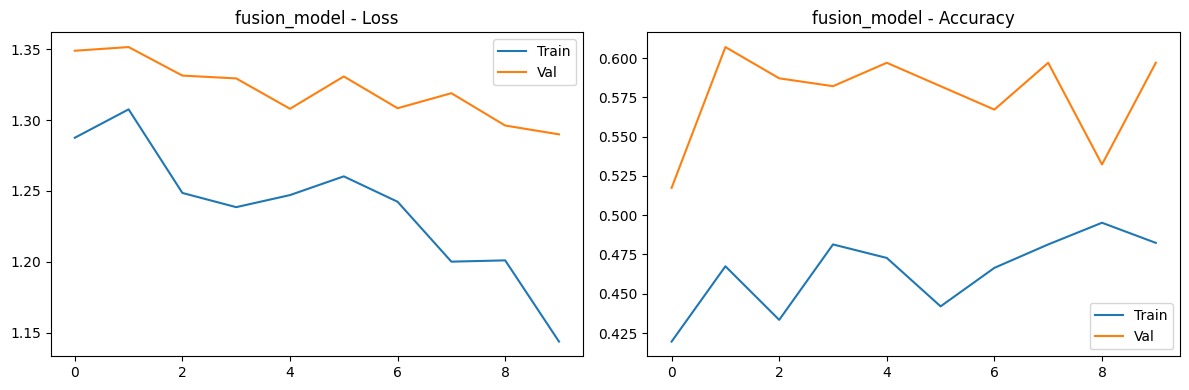

In [ ]:
plot_curves(
    [1.2875,1.3075,1.2486,1.2386,1.2471,1.2603,1.2424,1.2002,1.2011,1.1439],
    [1.3488,1.3514,1.3313,1.3293,1.3079,1.3307,1.3083,1.3189,1.2961,1.2899],
    [0.4196,0.4675,0.4334,0.4814,0.4728,0.4420,0.4665,0.4814,0.4952,0.4824],
    [0.5174,0.6070,0.5871,0.5821,0.5970,0.5821,0.5672,0.5970,0.5323,0.5970],
    'fusion_model')